# Prédire la gravité des accidents de la route en France

## 1. Contexte et objectif

**Le problème** : chaque année en France, des accidents de la route font des blessés et des morts. Quand un accident arrive, les secours et les forces de l'ordre doivent savoir vite s'il est grave. Comprendre quels facteurs (heure, météo, type de route, vitesse, type de véhicule...) sont liés aux accidents graves peut aider à mieux prévenir ces accidents.

**Les données** : j'utilise le fichier BAAC (Bulletin d'Analyse des Accidents Corporels), publié en open data sur data.gouv.fr par l'ONISR (Observatoire national interministériel de la sécurité routière). Chaque année, les forces de l'ordre y enregistrent les accidents corporels, répartis en 4 fichiers CSV : caractéristiques, lieux, véhicules et usagers. Pour commencer, je travaille sur l'année 2023, puis je pourrai ajouter d'autres années récentes (à partir de 2019).

**L'objectif** : construire un modèle de machine learning qui prédit si un usager impliqué dans un accident est gravement blessé ou non, à partir des informations disponibles sur l'accident, le lieu, le véhicule et la personne.

**Le type de problème** : j'ai un label connu (la gravité), donc c'est de l'apprentissage **supervisé**, et comme je veux prédire une catégorie (grave ou non), c'est un problème de **classification**. Je précise le choix exact du label dans la partie 5, après avoir regardé les données.

**Plan du notebook** :
1. Contexte et objectif
2. Présentation des données
3. Préparation et nettoyage des données
4. Exploration des données (EDA)
5. Type de problème et choix du label
6. Séparation train/test et standardisation
7. Gestion du déséquilibre des classes
8. Comparaison de plusieurs modèles
9. Réglage des hyperparamètres
10. Résultats, limites et pistes d'amélioration
11. Sauvegarde du modèle et déploiement

In [1]:
import glob
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid")

ANNEES = [2023]   # années à charger (je pourrai ajouter 2022, 2021... en mettant leurs fichiers dans donnees_brutes)
RAPIDE = True     # True : comparaisons et réglages sur un sous-échantillon (rapide) / False : tout le jeu d'entraînement
GRAINE = 42       # pour que les résultats soient les mêmes à chaque exécution

## 2. Présentation des données

**D'où viennent les données ?** Du fichier BAAC, publié par le ministère de l'Intérieur (ONISR) sur data.gouv.fr sous licence ouverte. Ce sont les forces de l'ordre (police, gendarmerie) qui remplissent une fiche pour chaque accident corporel, c'est-à-dire un accident sur une voie ouverte à la circulation, impliquant au moins un véhicule et faisant au moins une victime. Je n'ai pas un seul tableau : j'ai **4 fichiers CSV par année**, séparés par des points-virgules, que je dois relier moi-même.

| Fichier | Une ligne = | Taille en 2023 | Contenu |
|---|---|---|---|
| `carac` (caractéristiques) | un **accident** | 54 822 lignes | date, heure, luminosité, météo, localisation, type de collision |
| `lieux` | un **lieu** (plusieurs par accident possibles) | 70 860 lignes | type de route, vitesse maximale autorisée, état de la chaussée, nombre de voies |
| `vehicules` | un **véhicule** | 93 585 lignes | type de véhicule, point de choc, manœuvre, motorisation |
| `usagers` | une **personne** | 125 789 lignes | gravité (`grav`), sexe, année de naissance, place, équipement de sécurité |

**La clé pour relier les fichiers** : `Num_Acc` (numéro de l'accident), et `id_vehicule` pour relier une personne à son véhicule.

**Le label** : `grav`, la gravité des blessures de la personne. D'après la documentation de l'ONISR : 1 = indemne, 2 = tué, 3 = blessé hospitalisé, 4 = blessé léger (à confirmer dans le PDF de description des bases).

**Les unités** : la vitesse maximale autorisée (`vma`) est en km/h, l'âge en années, l'heure de 0 à 23. La plupart des autres colonnes (`lum`, `atm`, `catr`, `catv`, `surf`...) sont des **codes**, c'est-à-dire des catégories : un `lum = 5` ne veut pas dire « plus lumineux » qu'un `lum = 1`.

In [2]:
def lire(chemin):
    # les fichiers sont séparés par des points-virgules (sinon j'essaie la virgule)
    tab = pd.read_csv(chemin, sep=";", low_memory=False)
    if tab.shape[1] == 1:
        tab = pd.read_csv(chemin, sep=",", low_memory=False)
    return tab


def trouver(motif):
    # je cherche UN seul fichier qui correspond au motif (en ignorant le fichier des immatriculations)
    fichiers = [f for f in glob.glob(f"donnees_brutes/{motif}") if "immatricul" not in f]
    if len(fichiers) != 1:
        raise FileNotFoundError(f"Je cherche un fichier pour '{motif}' dans donnees_brutes, j'en trouve {len(fichiers)} : {fichiers}")
    return fichiers[0]


carac, lieux, usagers, vehicules = [], [], [], []
for annee in ANNEES:
    carac.append(lire(trouver(f"car*{annee}.csv")))
    lieux.append(lire(trouver(f"lieux*{annee}.csv")))
    usagers.append(lire(trouver(f"usagers*{annee}.csv")))
    vehicules.append(lire(trouver(f"vehicules*{annee}.csv")))

carac = pd.concat(carac, ignore_index=True)
lieux = pd.concat(lieux, ignore_index=True)
usagers = pd.concat(usagers, ignore_index=True)
vehicules = pd.concat(vehicules, ignore_index=True)

print("caracteristiques :", carac.shape)
print("lieux :", lieux.shape)
print("usagers :", usagers.shape)
print("vehicules :", vehicules.shape)

caracteristiques : (54822, 15)
lieux : (70860, 18)
usagers : (125789, 16)
vehicules : (93585, 11)


### Fichier caractéristiques (`carac`) : un accident par ligne

Il y a **54 822 lignes pour 54 822 accidents** : une ligne par accident, identifié par `Num_Acc`, qui sert de clé pour relier les fichiers. Une seule colonne a des cases vides, `adr` (l'adresse), mais ça ne veut pas dire que le fichier est propre : dans ces données, une valeur « non renseignée » est souvent notée `-1` au lieu d'être laissée vide, donc pandas ne la voit pas comme vide. Je les chercherai dans la partie nettoyage.

Autres points : `lat` et `long` sont lues comme du **texte** parce que les décimales sont écrites avec une virgule (`48,866386`), et `hrmn` (l'heure) est aussi du texte (`06:00`). Je les convertirai. Enfin, `lum`, `agg`, `int`, `atm` et `col` sont des codes de catégories, pas des quantités.

In [3]:
for nom, tab in [("carac", carac), ("lieux", lieux), ("usagers", usagers), ("vehicules", vehicules)]:
    print("=====", nom, tab.shape)
    display(tab.head(3))

===== carac (54822, 15)


,Num_Acc,jour,mois,an,hrmn,lum,dep,com,agg,int,atm,col,adr,lat,long
0,202300000001,7,5,2023,06:00,1,75,75101,2,4,2,7,RUE DE RIVOLI,"48,86638600","2,32347100"
1,202300000002,7,5,2023,05:30,5,94,94080,2,1,3,6,Avenue de Paris,"48,84547782","2,42868146"
2,202300000003,7,5,2023,20:50,1,94,94022,2,3,2,1,Avenue du Général Leclerc,"48,76240000","2,40655000"


===== lieux (70860, 18)


,Num_Acc,catr,voie,v1,v2,circ,nbv,vosp,prof,pr,pr1,plan,lartpc,larrout,surf,infra,situ,vma
0,202300000001,4,RUE DE RIVOLI,0,NaN,1,2,0,1,-1,-1,1,NaN,-1,2,0,1,30
1,202300000001,4,RUE SAINT FLORENTIN,0,NaN,1,1,0,1,-1,-1,1,NaN,-1,2,0,1,30
2,202300000002,3,120,0,NaN,2,3,2,1,-1,-1,1,NaN,-1,2,0,1,50


===== usagers (125789, 16)


,Num_Acc,id_usager,id_vehicule,num_veh,place,catu,grav,sexe,an_nais,trajet,secu1,secu2,secu3,locp,actp,etatp
0,202300000001,203 851 184,155 680 557,A01,1,1,4,1,1978.0,5,2,0,-1,-1,-1,-1
1,202300000002,203 851 182,155 680 556,A01,1,1,1,2,1997.0,9,1,0,-1,-1,-1,-1
2,202300000002,203 851 183,155 680 556,A01,10,3,3,1,1997.0,9,0,-1,-1,2,3,1


===== vehicules (93585, 11)


,Num_Acc,id_vehicule,num_veh,senc,catv,obs,obsm,choc,manv,motor,occutc
0,202300000001,155 680 557,A01,1,30,0,0,5,1,1,NaN
1,202300000002,155 680 556,A01,2,7,0,1,1,1,1,NaN
2,202300000003,155 680 554,B01,1,2,0,2,1,16,1,NaN


### Fichier lieux : un accident peut avoir plusieurs lignes

En comparant les fichiers, j'ai remarqué que `lieux` contient 70 860 lignes alors qu'il y a seulement 54 822 accidents dans `carac`. Un accident peut donc avoir plusieurs lignes de lieu (par exemple à un carrefour, une ligne par voie). Si je joignais les fichiers sans corriger ça, certains accidents seraient dupliqués et le modèle verrait plusieurs fois le même accident.

**Ce que j'ai mesuré** : 15 870 accidents (environ 29 %) ont plusieurs lignes de lieu. Pour ces accidents, la catégorie de route (`catr`) ne change jamais et l'état de la chaussée (`surf`) change très rarement (350 accidents). En revanche, la vitesse maximale autorisée (`vma`) change pour 5 169 accidents et le régime de circulation (`circ`) pour 6 018 accidents.

**Mon choix** : je garde une seule ligne par accident, celle où la vitesse maximale autorisée est la plus élevée. J'ai fait cette hypothèse parce que la route la plus rapide d'un carrefour me semble plus susceptible de jouer sur la gravité d'un accident.

**Limite** : c'est un choix de modélisation, pas une vérité. Il pourrait introduire un petit biais pour les accidents à plusieurs routes. Je le note dans les limites à la fin du notebook.

In [4]:
# combien de lignes de lieu par accident ?
print(lieux["Num_Acc"].value_counts().value_counts().sort_index())

# je garde, pour chaque accident, la ligne avec la vitesse maximale autorisée la plus élevée
lieux_unique = (
    lieux.sort_values("vma", ascending=False, kind="stable")
    .drop_duplicates("Num_Acc", keep="first")
    .sort_values("Num_Acc")
    .reset_index(drop=True)
)

print(lieux_unique.shape)
print("un seul lieu par accident :", lieux_unique["Num_Acc"].is_unique)

count
1    38952
2    15715
3      143
4       11
5        1
Name: count, dtype: int64
(54822, 18)
un seul lieu par accident : True


### Fichier usagers : la gravité, notre variable à prédire

Le fichier `usagers` contient une ligne par personne impliquée dans un accident (125 789 personnes pour 54 822 accidents). C'est dans ce fichier que se trouve la variable `grav`, la gravité des blessures, que je vais essayer de prédire.

**Ce que j'ai vérifié** : tous les accidents de `usagers` existent dans `carac` et aucun identifiant de personne n'apparaît deux fois. Les fichiers sont donc cohérents entre eux.

**Ce que j'ai remarqué** :
- La gravité est **déséquilibrée** : 42,5 % d'indemnes, 39,4 % de blessés légers, 15,3 % de blessés hospitalisés et seulement 2,7 % de tués. Les cas graves sont rares, comme dans un problème de détection de fraude. L'accuracy seule risque donc d'être trompeuse et je regarderai aussi la precision, le recall et le F1.
- **118 personnes n'ont pas de gravité renseignée** (`-1`) : je ne peux pas les utiliser pour entraîner un modèle, je les retire au nettoyage.
- `an_nais` a 2 598 valeurs manquantes (environ 2 %). J'en tire l'âge de la personne.
- Beaucoup de colonnes contiennent des `-1` qui veulent dire « non renseigné » ou « non concerné » : je les traite dans la partie 3.
- `id_usager`, `id_vehicule` et `num_veh` sont des identifiants. Ils me servent à relier les fichiers, mais je ne les donne pas au modèle.

**Point d'attention** : ce fichier est au niveau de la personne, pas de l'accident. Plusieurs personnes d'un même accident se ressemblent (même route, même météo). Je dois y penser au moment de séparer train et test, pour ne pas avoir des personnes d'un même accident des deux côtés.

In [5]:
print(usagers["grav"].value_counts().sort_index())
print()
print("accidents dans usagers :", usagers["Num_Acc"].nunique())
print("accidents de usagers absents de carac :", (~usagers["Num_Acc"].isin(carac["Num_Acc"])).sum())
print("id_usager en double :", usagers["id_usager"].duplicated().sum())

grav
-1      118
 1    53399
 2     3398
 3    19271
 4    49603
Name: count, dtype: int64

accidents dans usagers : 54822
accidents de usagers absents de carac : 0
id_usager en double : 0


### Fichier vehicules : un véhicule par ligne

Le fichier `vehicules` contient une ligne par véhicule impliqué dans un accident (93 585 véhicules). Il décrit le type de véhicule (`catv`), l'obstacle heurté (`obs`, `obsm`), le point de choc (`choc`), la manœuvre avant l'accident (`manv`) et la motorisation (`motor`).

**Ce que j'ai vérifié** : chaque véhicule apparaît une seule fois (`id_vehicule` unique), tous les accidents de `vehicules` existent dans `carac`, et chaque personne du fichier `usagers` est bien rattachée à un véhicule présent dans `vehicules`. Les liens entre les fichiers sont donc cohérents.

**Ce que j'ai remarqué** :
- Presque toutes les colonnes sont complètes, sauf `occutc` (nombre d'occupants dans un transport en commun) qui est vide pour 92 747 véhicules sur 93 585. Cette colonne ne concerne que les bus et les cars, je la supprime.
- Les colonnes sont des codes (catégories), pas des quantités : je dois m'en souvenir au moment de préparer les données pour les modèles.

**Conclusion sur les 4 fichiers** : après avoir gardé un seul lieu par accident, je peux relier les fichiers sans dupliquer de lignes. L'unité d'analyse sera **la personne** (une ligne de `usagers`), à laquelle j'ajoute les informations de son véhicule, de l'accident et du lieu.

In [6]:
print("lignes :", len(vehicules))
print("id_vehicule uniques :", vehicules["id_vehicule"].nunique())
print("accidents absents de carac :", (~vehicules["Num_Acc"].isin(carac["Num_Acc"])).sum())
print("id_vehicule de usagers absents de vehicules :", (~usagers["id_vehicule"].isin(vehicules["id_vehicule"])).sum())
print()
print(vehicules.isna().sum())

lignes : 93585
id_vehicule uniques : 93585
accidents absents de carac : 0
id_vehicule de usagers absents de vehicules : 0

Num_Acc            0
id_vehicule        0
num_veh            0
senc               0
catv               0
obs                0
obsm               0
choc               0
manv               0
motor              0
occutc         92747
dtype: int64


## 3. Préparation et nettoyage des données

C'est la partie « data engineering » : je pars de 4 fichiers bruts et je construis un tableau propre, prêt pour le machine learning.

### 3.1 Jointure des 4 fichiers

L'unité d'analyse est la personne (une ligne de `usagers`). Je lui ajoute les informations de son véhicule, de son accident et de son lieu avec des `merge` (comme des jointures SQL). Je garde toutes les personnes (`how="left"`) et j'ajoute `validate="many_to_one"` : pandas vérifie alors qu'une personne ne peut correspondre qu'à une seule ligne de chaque autre tableau, et s'arrête avec une erreur si ce n'est pas le cas. Ça m'évite de dupliquer des lignes sans m'en rendre compte.

In [7]:
df = (
    usagers
    .merge(vehicules.drop(columns=["Num_Acc", "num_veh"]), on="id_vehicule", how="left", validate="many_to_one")
    .merge(carac, on="Num_Acc", how="left", validate="many_to_one")
    .merge(lieux_unique, on="Num_Acc", how="left", validate="many_to_one")
)

print(df.shape)
print("lignes de usagers :", len(usagers))
print("id_usager uniques :", df["id_usager"].is_unique)
print("sans correspondance véhicule :", df["catv"].isna().sum())
print("sans correspondance carac :", df["jour"].isna().sum())
print("sans correspondance lieux :", df["catr"].isna().sum())

(125789, 55)
lignes de usagers : 125789
id_usager uniques : True
sans correspondance véhicule : 0
sans correspondance carac : 0
sans correspondance lieux : 0


### 3.2 Personnes sans gravité renseignée

Les personnes dont la gravité vaut `-1` n'ont pas de label : le modèle n'aurait pas de réponse à apprendre. Je les retire (118 personnes en 2023).

In [8]:
df = df[df["grav"] != -1].copy()
print("après retrait des sans-label :", df.shape)

après retrait des sans-label : (125671, 55)


### 3.3 Convertir les colonnes de texte en nombres

Plusieurs colonnes de nombres sont lues comme du **texte** : les décimales sont écrites avec une virgule (`5,5`), et certaines valeurs contiennent un espace devant (`' -1'`). Je nettoie le texte (espaces, virgule remplacée par un point) puis je convertis en nombres. Avec `errors="coerce"`, ce qui n'est vraiment pas un nombre devient une valeur manquante. Je compare avant et après pour voir combien de valeurs sont concernées : très peu en 2023 (127 pour `nbv`, 24 pour `pr`, 1 147 pour `pr1`).

In [9]:
colonnes_texte = ["nbv", "pr", "pr1", "larrout", "lartpc", "lat", "long"]

avant = df[colonnes_texte].isna().sum()
for col in colonnes_texte:
    df[col] = pd.to_numeric(df[col].astype(str).str.strip().str.replace(",", "."), errors="coerce")
apres = df[colonnes_texte].isna().sum()

df["actp"] = df["actp"].astype(str).str.strip()   # actp mélange chiffres et lettres : je la garde en texte

print(df[colonnes_texte].dtypes)
print()
print("valeurs devenues manquantes à cause de la conversion :")
print(apres - avant)

nbv        float64
pr         float64
pr1        float64
larrout    float64
lartpc     float64
lat        float64
long       float64
dtype: object

valeurs devenues manquantes à cause de la conversion :
nbv         127
pr           24
pr1        1147
larrout       0
lartpc        0
lat           0
long          0
dtype: int64


### 3.4 Les valeurs `-1` (non renseigné)

Dans ces données, `-1` veut dire « non renseigné » ou « non concerné ». Pandas ne les voit pas comme des cases vides, alors que ça en est. Je calcule la part de `-1` dans chaque colonne (y compris celles lues comme du texte, où le `-1` s'écrivait avec un espace) pour décider quoi garder.

**Mes décisions** :
- Je **supprime** les colonnes presque vides : `secu3` (98 % de `-1`), `etatp` (92 %), `larrout` (69 %), `lartpc`, `v2` et `occutc` (presque vides).
- Je supprime aussi `pr` et `pr1` (repères kilométriques sur la route, 33 % de `-1`, peu utiles pour décrire une circonstance), ainsi que `voie`, `adr`, `com`, `dep`, `lat`, `long` et `v1` : ce sont des identifiants ou des localisations trop précises pour cette première version. Ça pourra être une piste d'amélioration.
- Pour les colonnes de **catégories**, je garde `-1` comme une catégorie à part (« non renseigné ») : le fait qu'une information soit absente peut aussi apporter quelque chose.
- Pour les colonnes **numériques** (âge, vitesse autorisée, nombre de voies), je remplace `-1` et les valeurs impossibles par une valeur manquante, que je remplirai avec la médiane (calculée sur le train seulement, pour ne pas faire fuiter d'information du test).

In [10]:
def part_moins_un(tab):
    res = {}
    for col in tab.columns:
        if pd.api.types.is_numeric_dtype(tab[col]):
            res[col] = (tab[col] == -1).mean() * 100
        else:
            res[col] = (tab[col].astype(str).str.strip() == "-1").mean() * 100
    res = pd.Series(res)
    return res[res > 0].sort_values(ascending=False).round(1)


print("part de -1 par colonne (en %) :")
print(part_moins_un(df))

part de -1 par colonne (en %) :
secu3      98.1
etatp      92.0
larrout    68.8
locp       50.3
actp       50.2
secu2      44.0
pr1        33.4
pr         33.1
v1         19.1
circ        6.7
trajet      1.9
sexe        1.8
nbv         1.8
secu1       1.7
vma         1.7
vosp        0.9
infra       0.8
motor       0.2
senc        0.1
obs         0.1
choc        0.1
obsm        0.0
manv        0.0
col         0.0
situ        0.0
surf        0.0
prof        0.0
plan        0.0
int         0.0
atm         0.0
catv        0.0
lum         0.0
place       0.0
dtype: float64


### 3.5 Valeurs aberrantes et nouvelles variables

Une **valeur aberrante** est une valeur impossible ou très improbable, comme un âge de 250 ans ou une vitesse autorisée de 0 km/h. Je repère celles que je peux détecter avec du bon sens, puis je les remplace par une valeur manquante :
- **âge** : entre 0 et 100 ans ;
- **vitesse maximale autorisée** : entre 5 et 130 km/h ;
- **nombre de voies** : entre 0 et 12.

Je crée aussi des variables plus utiles pour un modèle : l'**âge** (année de l'accident moins année de naissance), l'**heure** de l'accident (0 à 23) et le **jour de la semaine**.

In [11]:
# nouvelles variables
df["age"] = df["an"] - df["an_nais"]
df["heure"] = pd.to_numeric(df["hrmn"].astype(str).str.slice(0, 2), errors="coerce")
df["jour_semaine"] = pd.to_datetime({"year": df["an"], "month": df["mois"], "day": df["jour"]}, errors="coerce").dt.day_of_week
df["jour_semaine"] = df["jour_semaine"].fillna(-1).astype(int)

# valeurs aberrantes -> valeur manquante
print("âges impossibles :", ((df["age"] < 0) | (df["age"] > 100)).sum())
print("vitesses impossibles ou non renseignées :", (~df["vma"].between(5, 130)).sum())
print("nombres de voies impossibles ou non renseignés :", (~df["nbv"].between(0, 12)).sum())

df["age"] = df["age"].where(df["age"].between(0, 100))
df["vma"] = df["vma"].where(df["vma"].between(5, 130))
df["nbv"] = df["nbv"].where(df["nbv"].between(0, 12))

print()
display(df[["age", "heure", "vma", "nbv"]].describe().round(1))

âges impossibles : 9
vitesses impossibles ou non renseignées : 2107
nombres de voies impossibles ou non renseignés : 2436



,age,heure,vma,nbv
count,123182.0,125671.0,123564.0,123235.0
mean,38.7,13.5,61.4,2.3
std,19.1,5.5,24.1,1.2
min,0.0,0.0,10.0,0.0
25%,23.0,9.0,50.0,2.0
50%,35.0,14.0,50.0,2.0
75%,52.0,18.0,80.0,2.0
max,100.0,23.0,130.0,12.0


### 3.6 Le tableau final et sa sauvegarde

Je garde seulement les colonnes utiles : 4 variables numériques et des variables de catégories. Je convertis les catégories en texte, pour que le modèle les traite comme des catégories et pas comme des quantités. Je garde `Num_Acc` (pour séparer train et test sans mélanger les accidents) et `grav` (le label), mais ils ne serviront pas à prédire.

**Sauvegarde** : j'enregistre le tableau propre dans le dossier `donnees_propres` en deux formats. Le **CSV** se lit partout, mais il est lourd et ne garde pas les types des colonnes. Le **Parquet** est un format binaire, compressé, rangé par colonnes : il est plus petit, plus rapide à relire et il garde les types. En pratique, les projets de données utilisent surtout du Parquet.

In [12]:
COL_NUM = ["age", "heure", "vma", "nbv"]
COL_CAT = ["place", "catu", "sexe", "trajet", "secu1", "secu2", "locp", "actp",
           "senc", "catv", "obs", "obsm", "choc", "manv", "motor",
           "lum", "agg", "int", "atm", "col", "mois", "jour_semaine",
           "catr", "circ", "vosp", "prof", "plan", "surf", "infra", "situ"]

df_clean = df[["Num_Acc", "grav"] + COL_NUM + COL_CAT].copy()
for col in COL_CAT:
    df_clean[col] = df_clean[col].astype(str).str.strip()

print(df_clean.shape)
print()
print("valeurs manquantes :")
print(df_clean[COL_NUM].isna().sum())

os.makedirs("donnees_propres", exist_ok=True)
df_clean.to_csv("donnees_propres/accidents_propres.csv", index=False)
try:
    df_clean.to_parquet("donnees_propres/accidents_propres.parquet", index=False)
    print("Parquet sauvegardé")
except Exception as erreur:
    print("Parquet non sauvegardé (il faut pip install pyarrow) :", erreur)

(125671, 36)

valeurs manquantes :
age      2489
heure       0
vma      2107
nbv      2436
dtype: int64
Parquet sauvegardé


## 4. Exploration des données (EDA)

Avant de modéliser, je regarde les données : comment se répartit la gravité, et quelles circonstances sont liées à plus de cas graves. Pour comparer facilement, je crée une variable `grave` : 1 si la personne est tuée ou hospitalisée, 0 si elle est indemne ou blessée légèrement (je justifie ce choix dans la partie 5).

Pour chaque graphique, je regarde le **taux de personnes graves** par catégorie. La ligne rouge en pointillés est le taux moyen : au-dessus, la catégorie est plus risquée que la moyenne. J'ignore les catégories avec moins de 300 personnes, car leur taux n'est pas fiable.

grav
Indemne         42.5
Blessé léger    39.5
Hospitalisé     15.3
Tué              2.7
Name: count, dtype: float64


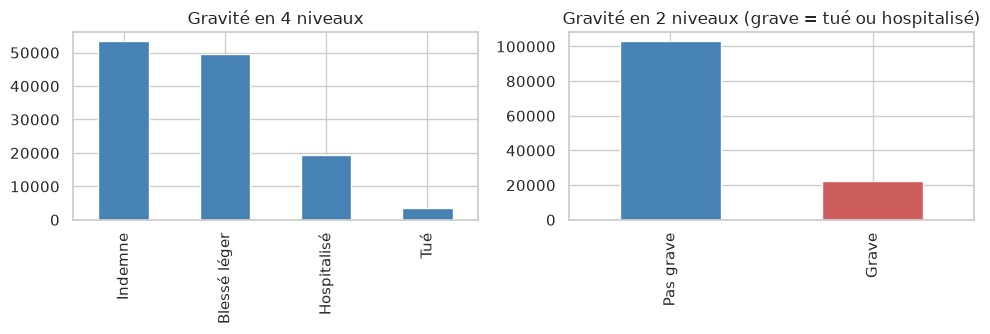

Taux de graves : 18.0 %
Accuracy d'un modèle qui répond toujours 'pas grave' : 82.0 %


In [13]:
df_clean["grave"] = df_clean["grav"].isin([2, 3]).astype(int)

noms_grav = {1: "Indemne", 2: "Tué", 3: "Hospitalisé", 4: "Blessé léger"}
repartition = df_clean["grav"].map(noms_grav).value_counts()
print((repartition / len(df_clean) * 100).round(1))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
repartition.loc[["Indemne", "Blessé léger", "Hospitalisé", "Tué"]].plot.bar(ax=axes[0], color="steelblue")
axes[0].set_title("Gravité en 4 niveaux")
axes[0].set_xlabel("")
df_clean["grave"].map({0: "Pas grave", 1: "Grave"}).value_counts().plot.bar(ax=axes[1], color=["steelblue", "indianred"])
axes[1].set_title("Gravité en 2 niveaux (grave = tué ou hospitalisé)")
axes[1].set_xlabel("")
plt.tight_layout()
plt.show()

print(f"Taux de graves : {df_clean['grave'].mean() * 100:.1f} %")
print(f"Accuracy d'un modèle qui répond toujours 'pas grave' : {(1 - df_clean['grave'].mean()) * 100:.1f} %")

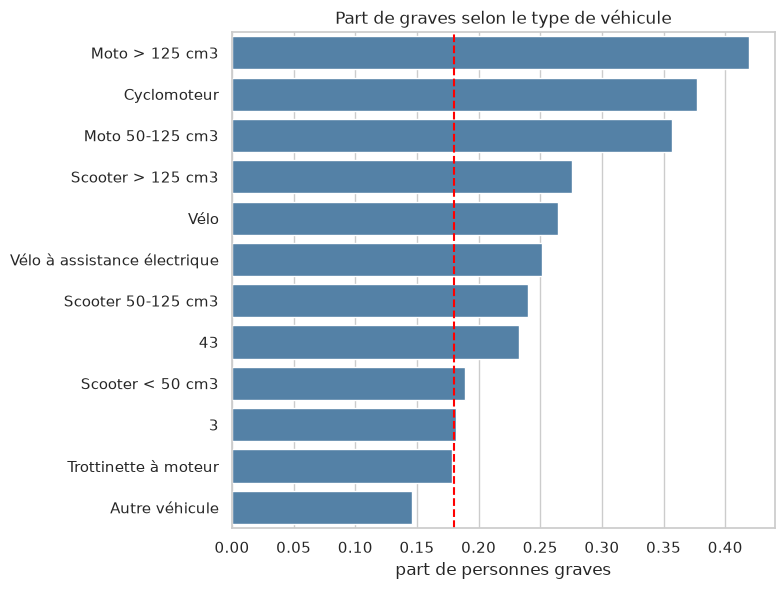

Le plus élevé : Moto > 125 cm3 (41.9 %, 8709 personnes) / le plus bas : Autocar (4.4 %, 611 personnes)


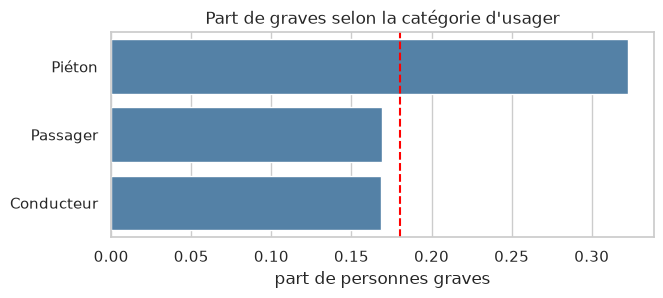

Le plus élevé : Piéton (32.3 %, 9518 personnes) / le plus bas : Conducteur (16.9 %, 93347 personnes)


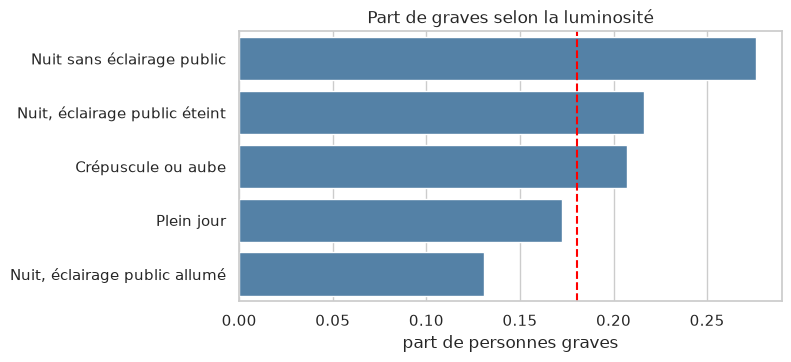

Le plus élevé : Nuit sans éclairage public (27.6 %, 13818 personnes) / le plus bas : Nuit, éclairage public allumé (13.1 %, 19335 personnes)


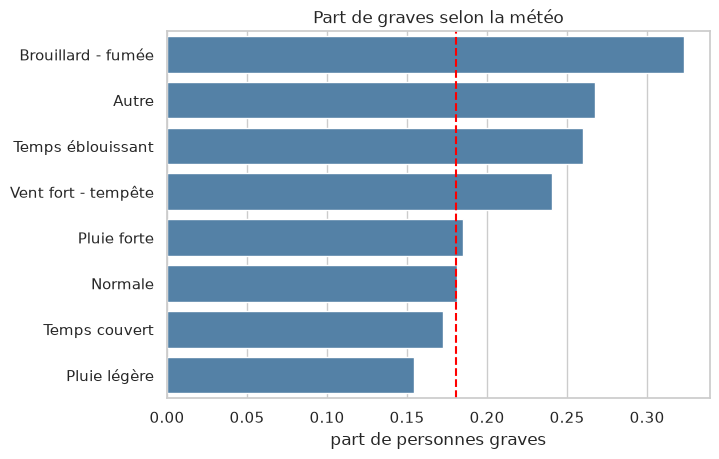

Le plus élevé : Brouillard - fumée (32.3 %, 508 personnes) / le plus bas : Pluie légère (15.5 %, 14955 personnes)


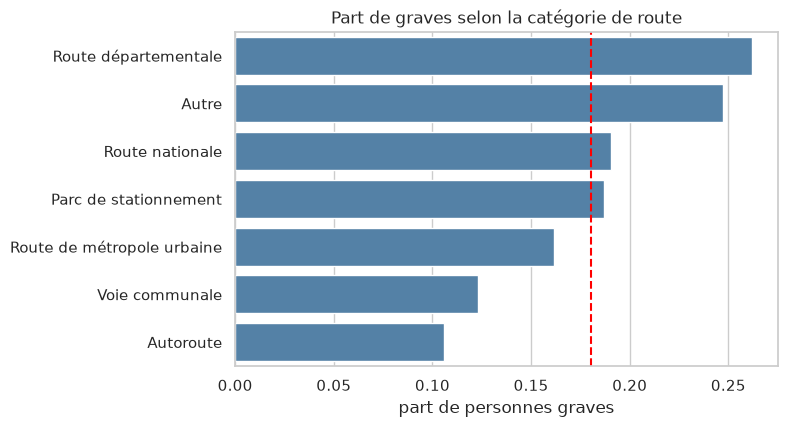

Le plus élevé : Route départementale (26.2 %, 47261 personnes) / le plus bas : Autoroute (10.6 %, 14057 personnes)


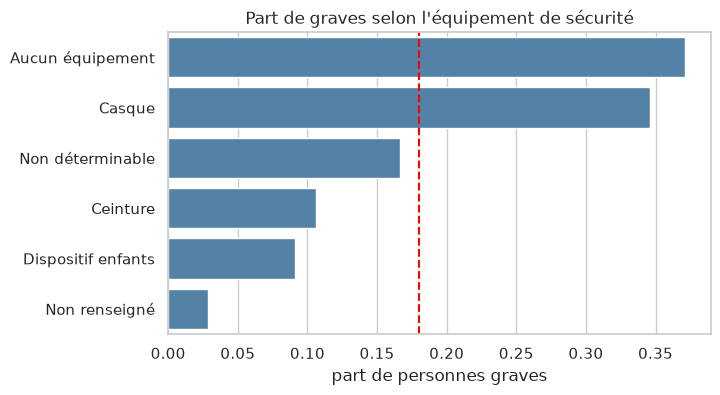

Le plus élevé : Aucun équipement (37.1 %, 11937 personnes) / le plus bas : Non renseigné (2.8 %, 2184 personnes)


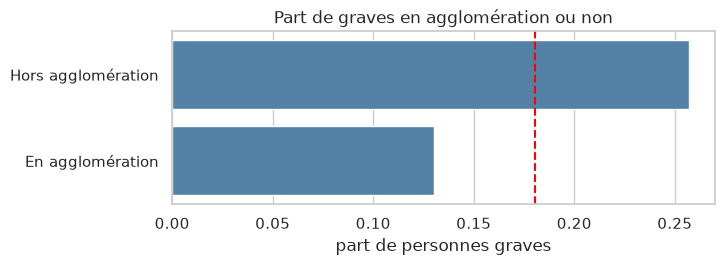

Le plus élevé : Hors agglomération (25.7 %, 49701 personnes) / le plus bas : En agglomération (13.0 %, 75970 personnes)


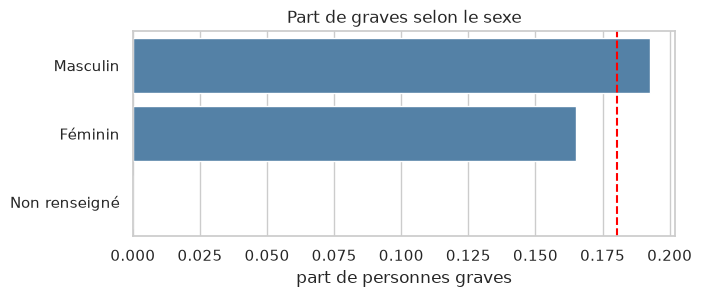

Le plus élevé : Masculin (19.2 %, 84011 personnes) / le plus bas : Non renseigné (0.0 %, 2315 personnes)


In [14]:
NOMS = {
    "catu": {"1": "Conducteur", "2": "Passager", "3": "Piéton"},
    "sexe": {"1": "Masculin", "2": "Féminin", "-1": "Non renseigné"},
    "agg": {"1": "Hors agglomération", "2": "En agglomération"},
    "lum": {"1": "Plein jour", "2": "Crépuscule ou aube", "3": "Nuit sans éclairage public",
            "4": "Nuit, éclairage public éteint", "5": "Nuit, éclairage public allumé"},
    "atm": {"-1": "Non renseigné", "1": "Normale", "2": "Pluie légère", "3": "Pluie forte", "4": "Neige - grêle",
            "5": "Brouillard - fumée", "6": "Vent fort - tempête", "7": "Temps éblouissant", "8": "Temps couvert", "9": "Autre"},
    "catr": {"1": "Autoroute", "2": "Route nationale", "3": "Route départementale", "4": "Voie communale",
             "5": "Hors réseau public", "6": "Parc de stationnement", "7": "Route de métropole urbaine", "9": "Autre"},
    "surf": {"-1": "Non renseigné", "1": "Normale", "2": "Mouillée", "3": "Flaques", "4": "Inondée", "5": "Enneigée",
             "6": "Boue", "7": "Verglacée", "8": "Corps gras - huile", "9": "Autre"},
    "secu1": {"-1": "Non renseigné", "0": "Aucun équipement", "1": "Ceinture", "2": "Casque", "3": "Dispositif enfants",
              "4": "Gilet réfléchissant", "5": "Airbag (2-3 roues)", "6": "Gants (2-3 roues)", "7": "Gants + airbag",
              "8": "Non déterminable", "9": "Autre"},
    "catv": {"1": "Vélo", "2": "Cyclomoteur", "7": "Voiture (VL)", "10": "Utilitaire (VU)", "13": "Poids lourd 3,5-7,5 t",
             "14": "Poids lourd > 7,5 t", "30": "Scooter < 50 cm3", "31": "Moto 50-125 cm3", "32": "Scooter 50-125 cm3",
             "33": "Moto > 125 cm3", "34": "Scooter > 125 cm3", "37": "Autobus", "38": "Autocar",
             "50": "Trottinette à moteur", "80": "Vélo à assistance électrique", "99": "Autre véhicule"},
}   # codes d'après la documentation ONISR (à confirmer dans le PDF)


def taux_par(colonne, titre, min_n=300, top=None):
    t = df_clean.groupby(colonne)["grave"].agg(taux="mean", n="size").reset_index()
    t = t[t["n"] >= min_n].sort_values("taux", ascending=False)
    t["categorie"] = t[colonne].map(lambda v: NOMS.get(colonne, {}).get(v, v))
    haut, bas = t.iloc[0], t.iloc[-1]      # le plus et le moins risqué, sur toutes les catégories
    if top:
        t = t.head(top)                    # (on n'affiche que les "top" plus risquées)
    plt.figure(figsize=(7, 0.42 * len(t) + 1.4))
    sns.barplot(data=t, y="categorie", x="taux", color="steelblue")
    plt.axvline(df_clean["grave"].mean(), color="red", linestyle="--")
    plt.title(titre)
    plt.xlabel("part de personnes graves")
    plt.ylabel("")
    plt.show()
    print(f"Le plus élevé : {haut['categorie']} ({haut['taux'] * 100:.1f} %, {int(haut['n'])} personnes) / "
          f"le plus bas : {bas['categorie']} ({bas['taux'] * 100:.1f} %, {int(bas['n'])} personnes)")


taux_par("catv", "Part de graves selon le type de véhicule", top=12)
taux_par("catu", "Part de graves selon la catégorie d'usager")
taux_par("lum", "Part de graves selon la luminosité")
taux_par("atm", "Part de graves selon la météo")
taux_par("catr", "Part de graves selon la catégorie de route")
taux_par("secu1", "Part de graves selon l'équipement de sécurité")
taux_par("agg", "Part de graves en agglomération ou non")
taux_par("sexe", "Part de graves selon le sexe")

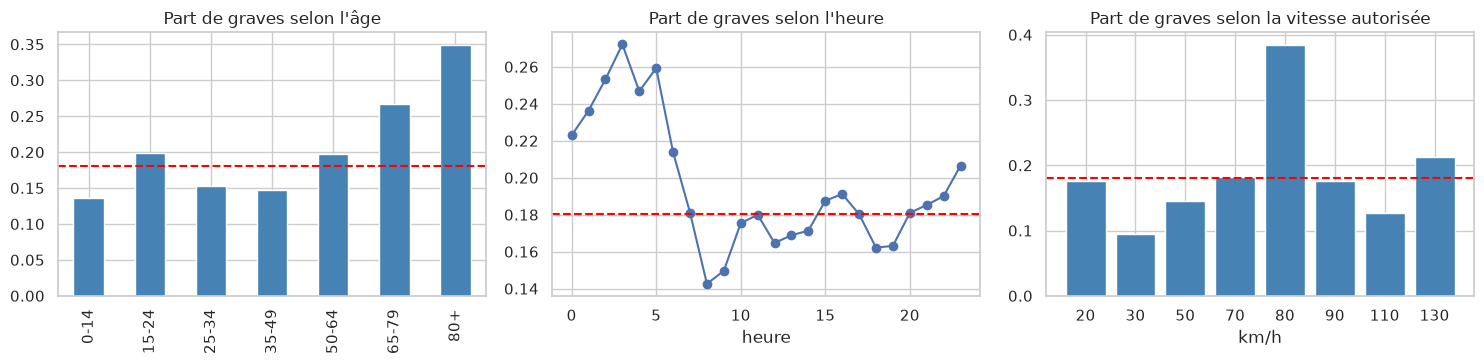

Tranche d'âge la plus touchée : 80+ (34.9 %)
Heure la plus touchée : 3 h (27.2 %)
Vitesse autorisée la plus touchée : 80 km/h (38.5 %)


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))

# selon l'âge
tranches = pd.cut(df_clean["age"], bins=[-1, 14, 24, 34, 49, 64, 79, 101],
                  labels=["0-14", "15-24", "25-34", "35-49", "50-64", "65-79", "80+"])
t_age = df_clean.groupby(tranches, observed=True)["grave"].mean()
t_age.plot.bar(ax=axes[0], color="steelblue")
axes[0].set_title("Part de graves selon l'âge")
axes[0].axhline(df_clean["grave"].mean(), color="red", linestyle="--")
axes[0].set_xlabel("")

# selon l'heure
t_heure = df_clean.groupby("heure")["grave"].mean()
axes[1].plot(t_heure.index, t_heure.values, marker="o")
axes[1].set_title("Part de graves selon l'heure")
axes[1].set_xlabel("heure")
axes[1].axhline(df_clean["grave"].mean(), color="red", linestyle="--")

# selon la vitesse maximale autorisée
t_vma = df_clean.groupby("vma")["grave"].agg(["mean", "size"])
t_vma = t_vma[t_vma["size"] >= 300]
axes[2].bar(t_vma.index.astype(int).astype(str), t_vma["mean"], color="steelblue")
axes[2].set_title("Part de graves selon la vitesse autorisée")
axes[2].set_xlabel("km/h")
axes[2].axhline(df_clean["grave"].mean(), color="red", linestyle="--")

plt.tight_layout()
plt.show()

print("Tranche d'âge la plus touchée :", t_age.idxmax(), f"({t_age.max() * 100:.1f} %)")
print("Heure la plus touchée :", int(t_heure.idxmax()), f"h ({t_heure.max() * 100:.1f} %)")
print("Vitesse autorisée la plus touchée :", int(t_vma['mean'].idxmax()), f"km/h ({t_vma['mean'].max() * 100:.1f} %)")

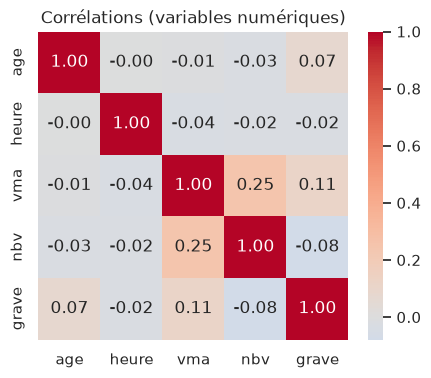

part de valeurs manquantes (%) :
age      2.0
heure    0.0
vma      1.7
nbv      1.9
dtype: float64


In [16]:
# corrélation entre les variables numériques et la gravité
plt.figure(figsize=(5, 4))
sns.heatmap(df_clean[COL_NUM + ["grave"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Corrélations (variables numériques)")
plt.show()

# valeurs manquantes restantes
manquantes = df_clean[COL_NUM].isna().mean() * 100
print("part de valeurs manquantes (%) :")
print(manquantes.round(1))

### Ce que je retiens de l'EDA

**Le déséquilibre** : 42,5 % d'indemnes, 39,5 % de blessés légers, 15,3 % d'hospitalisés et 2,7 % de tués, soit **18,0 % de graves**. Un modèle qui répond toujours « pas grave » aurait 82,0 % d'accuracy.

**Les circonstances les plus liées aux cas graves** (taux de graves, à comparer aux 18 % de moyenne) :
- **Le type d'usager et de véhicule** : les piétons sont graves dans 32,3 % des cas (9 518 personnes) contre 16,9 % pour les conducteurs (93 347). Les motos de plus de 125 cm3 sont les plus touchées avec 41,9 % (8 709 personnes).
- **La route** : les routes départementales (26,2 %) contre les autoroutes (10,6 %), et hors agglomération (25,7 %) contre en agglomération (13,0 %). Par vitesse autorisée, le pire est à **80 km/h (38,5 %)**, alors que les routes à 30 km/h sont autour de 10 %.
- **La luminosité et l'heure** : la nuit sans éclairage public est à 27,6 % contre 13,1 % la nuit avec éclairage allumé. Le pic est à **3 h du matin (27,2 %)** et le minimum vers 8 h (environ 14 %).
- **L'âge** : la part de graves monte avec l'âge, jusqu'à 34,9 % chez les 80 ans et plus.
- **La météo** : le brouillard est à 32,3 %, mais sur seulement 508 personnes, donc ce chiffre est moins fiable.
- **Le sexe** : 19,2 % de graves chez les hommes, environ 16,5 % chez les femmes.

**Ce qui m'a fait réfléchir** :
- Le **casque** est associé à 34,5 % de graves et « aucun équipement » à 37,1 %, alors que la ceinture est à environ 10 %. Ça ne veut pas dire que le casque est dangereux : il concerne surtout les deux-roues motorisés, qui sont déjà les plus exposés. Le graphique mélange l'équipement et le type de véhicule : c'est une **corrélation**, pas une cause.
- Les catégories **« non renseigné »** sont presque jamais graves : 2,8 % pour l'équipement de sécurité (2 184 personnes) et **0 %** pour le sexe (2 315 personnes). Le fait qu'une information manque est donc lié à la gravité, probablement à cause de la façon dont les forces de l'ordre remplissent la fiche (c'est une hypothèse, je ne l'ai pas vérifiée). Le modèle risque d'utiliser ça, je le reprends dans les limites.
- Les **corrélations linéaires** sont faibles (âge 0,07, vitesse 0,11, nombre de voies -0,08). Ce n'est pas surprenant : les liens ne sont pas linéaires (la vitesse à 80 km/h est pire qu'à 130, et le risque dépend de l'heure par pics). Ça justifie d'utiliser des modèles à base d'arbres.

## 5. Type de problème et choix du label

**Apprentissage supervisé.** J'ai pour chaque personne la réponse que je veux prédire (`grav`) : le modèle apprend à partir d'exemples où la bonne réponse est connue. En apprentissage non supervisé, il n'y aurait pas de label et le modèle chercherait seulement des groupes ou des structures dans les données (par exemple des profils d'accidents), sans réponse à prédire.

**Classification.** Je prédis une catégorie (grave ou pas), pas un nombre comme un prix, qui serait de la régression.

**Ce n'est pas une série temporelle.** Les accidents ne dépendent pas de l'ordre dans lequel ils sont rangés : chaque personne est un exemple indépendant, décrit par ses caractéristiques. L'heure ou le mois sont juste des variables parmi d'autres.

**Choix du label.** La gravité a 4 niveaux, mais les « tués » ne sont que 2,7 % des personnes : un modèle à 4 classes aurait très peu d'exemples pour apprendre cette classe. Je regroupe donc en deux :
- **grave (1)** : blessé hospitalisé ou tué ;
- **pas grave (0)** : indemne ou blessé léger.

C'est un choix de modélisation, avec un avantage (suffisamment d'exemples de chaque côté) et une limite : on mélange deux niveaux de gravité très différents. Autre limite : la définition de « blessé hospitalisé » a changé en 2018 dans la saisie des forces de l'ordre, donc je n'utilise que des années récentes (2019 et après).

**Conséquence : le jeu de données est déséquilibré** (environ 18 % de graves). Un modèle qui répondrait toujours « pas grave » aurait déjà environ 82 % d'accuracy sans rien avoir appris. Pour évaluer correctement, je regarde surtout :
- le **recall** (parmi les personnes vraiment graves, combien le modèle en trouve) ;
- la **precision** (parmi celles qu'il appelle « graves », combien le sont vraiment) ;
- le **F1** (un compromis entre les deux) et la **PR-AUC** (qualité du classement des personnes, indépendante du seuil).

In [17]:
print("Répartition du label :")
print(df_clean["grave"].value_counts().rename({0: "pas grave", 1: "grave"}))
print(f"Part de graves : {df_clean['grave'].mean() * 100:.1f} %")

Répartition du label :
grave
pas grave    103002
grave         22669
Name: count, dtype: int64
Part de graves : 18.0 %


## 6. Séparation train/test et standardisation

**D'abord je sépare, ensuite je standardise.** Si je standardisais avant de séparer, la moyenne et l'écart-type seraient calculés avec les données du test : de l'information du test « fuiterait » dans l'entraînement (*data leakage*) et mon résultat serait trop optimiste. Je sépare donc d'abord, puis j'apprends les paramètres de standardisation **sur le train seulement**, et je les applique tels quels au test.

**Je sépare par accident, pas par personne.** Plusieurs personnes d'un même accident se ressemblent beaucoup (même route, même météo, même heure). Si certaines étaient dans le train et d'autres dans le test, le modèle pourrait « reconnaître » l'accident au lieu d'apprendre des règles générales. J'utilise donc `GroupShuffleSplit` avec `Num_Acc` comme groupe : tous les gens d'un même accident vont du même côté.

**Les 3 jeux** : 80 % pour l'entraînement (que je redécoupe en `fit` et `val` pour comparer et régler les modèles) et 20 % de **test**, que je n'ouvre qu'à la toute fin.

**Standardiser** (centrer-réduire) : pour les variables numériques, je soustrais la moyenne et je divise par l'écart-type, ce qui donne une moyenne de 0 et un écart-type de 1. Sans ça, une variable à grandes valeurs (comme la vitesse, de 30 à 130) pèserait plus qu'une variable à petites valeurs (comme le nombre de voies) pour certains modèles (régression logistique...). Les arbres n'en ont pas besoin, mais ça ne les gêne pas. Pour les catégories, je fais du **one-hot encoding** : chaque catégorie devient une colonne de 0 et de 1, sinon le modèle croirait qu'un code 5 est « plus grand » qu'un code 1. Les valeurs manquantes sont remplies par la **médiane** (numérique) ou par la catégorie `-1` (catégories), toujours apprises sur le train.

In [18]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

X = df_clean[COL_NUM + COL_CAT]
y = df_clean["grave"]
groupes = df_clean["Num_Acc"]

# 1) train / test, en gardant les accidents ensemble
decoupe = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=GRAINE)
i_train, i_test = next(decoupe.split(X, y, groups=groupes))
X_train, X_test = X.iloc[i_train], X.iloc[i_test]
y_train, y_test = y.iloc[i_train], y.iloc[i_test]
g_train, g_test = groupes.iloc[i_train], groupes.iloc[i_test]

# 2) dans le train : une partie pour apprendre (fit), une pour valider (val)
decoupe2 = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=GRAINE)
i_fit, i_val = next(decoupe2.split(X_train, y_train, groups=g_train))
X_fit, X_val = X_train.iloc[i_fit], X_train.iloc[i_val]
y_fit, y_val = y_train.iloc[i_fit], y_train.iloc[i_val]

print("train :", len(X_train), "personnes | test :", len(X_test), "personnes")
print("   dont fit :", len(X_fit), "| val :", len(X_val))
print("accidents communs au train et au test :", len(set(g_train) & set(g_test)))
print(f"part de graves : train {y_train.mean() * 100:.1f} % | test {y_test.mean() * 100:.1f} %")

# 3) le préparateur : standardisation des numériques, one-hot des catégories
transfo_num = Pipeline([("imputer", SimpleImputer(strategy="median")),
                        ("scaler", StandardScaler())])
transfo_cat = Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="-1")),
                        ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.01,
                                                 sparse_output=False, dtype=np.float32))])
preprocesseur = ColumnTransformer([("num", transfo_num, COL_NUM),
                                   ("cat", transfo_cat, COL_CAT)])

train : 100674 personnes | test : 24997 personnes
   dont fit : 75401 | val : 25273
accidents communs au train et au test : 0
part de graves : train 18.0 % | test 18.0 %


In [19]:
# vérification : après standardisation, le train a une moyenne de 0 et un écart-type de 1
prep_demo = clone(preprocesseur).fit(X_train)
num_train = prep_demo.named_transformers_["num"].transform(X_train[COL_NUM])
num_test = prep_demo.named_transformers_["num"].transform(X_test[COL_NUM])
print("TRAIN : moyenne", num_train.mean(axis=0).round(2), "| écart-type", num_train.std(axis=0).round(2))
print("TEST  : moyenne", num_test.mean(axis=0).round(2), "| écart-type", num_test.std(axis=0).round(2))
print()
print("colonnes après préparation :", prep_demo.transform(X_train.head(5)).shape[1])

TRAIN : moyenne [-0. -0. -0. -0.] | écart-type [1. 1. 1. 1.]
TEST  : moyenne [ 0.   -0.01 -0.01  0.  ] | écart-type [1.   1.01 0.99 1.  ]

colonnes après préparation : 204


## 7. Gestion du déséquilibre des classes

Seulement environ 18 % des personnes sont graves. Un modèle entraîné tel quel a tendance à répondre « pas grave » presque tout le temps, ce qui lui donne une bonne accuracy mais un mauvais recall. Je compare **4 façons de compenser** (plus la référence « rien »), sur la même base de départ :

| Stratégie | Principe |
|---|---|
| **Rien** | je laisse les données telles quelles (la référence) |
| **`class_weight='balanced'`** | le modèle donne plus de poids aux erreurs sur la classe rare |
| **Sous-échantillonnage** | je supprime au hasard des exemples de la classe majoritaire pour équilibrer |
| **Sur-échantillonnage aléatoire** | je recopie au hasard des exemples de la classe rare |
| **SMOTE** | je fabrique de **nouveaux exemples synthétiques** de la classe rare, en les plaçant entre deux exemples réels proches |

**Règle importante** : le rééquilibrage s'applique **uniquement sur le train**, jamais sur la validation ni sur le test. Sinon j'évaluerais mon modèle sur des données artificielles. Pour comparer, j'utilise le même modèle (Gradient Boosting) et je regarde la **PR-AUC** (qualité du classement, qui ne dépend pas du seuil) et le **recall** et la **precision** au seuil standard de 0,5.

In [20]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, average_precision_score, f1_score, precision_score,
                             recall_score, roc_auc_score)
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler


def scores(y_vrai, proba, seuil=0.5):
    pred = (proba >= seuil).astype(int)
    return {"precision": precision_score(y_vrai, pred, zero_division=0),
            "recall": recall_score(y_vrai, pred, zero_division=0),
            "F1": f1_score(y_vrai, pred, zero_division=0),
            "PR-AUC": average_precision_score(y_vrai, proba),
            "ROC-AUC": roc_auc_score(y_vrai, proba),
            "accuracy": accuracy_score(y_vrai, pred)}


def reduire(X_, y_, n=40000):
    # en mode rapide, je travaille sur un sous-échantillon du train (la validation reste complète)
    if RAPIDE and len(X_) > n:
        idx = X_.sample(n=n, random_state=GRAINE).index
        return X_.loc[idx], y_.loc[idx]
    return X_, y_


X_fit_r, y_fit_r = reduire(X_fit, y_fit)
g_fit_r = groupes.loc[X_fit_r.index]

prep_r = clone(preprocesseur).fit(X_fit_r)      # appris sur le train seulement
Xf_r = prep_r.transform(X_fit_r)
Xv_r = prep_r.transform(X_val)
print("fit :", Xf_r.shape, "| validation :", Xv_r.shape)

strategies = {
    "Rien (référence)": (None, None),
    "class_weight='balanced'": (None, "balanced"),
    "Sous-échantillonnage": (RandomUnderSampler(random_state=GRAINE), None),
    "Sur-échantillonnage aléatoire": (RandomOverSampler(random_state=GRAINE), None),
    "SMOTE": (SMOTE(random_state=GRAINE), None),
}

lignes = []
for nom, (echantillonneur, poids) in strategies.items():
    if echantillonneur is not None:
        Xr, yr = echantillonneur.fit_resample(Xf_r, y_fit_r)
    else:
        Xr, yr = Xf_r, y_fit_r
    m = HistGradientBoostingClassifier(class_weight=poids, random_state=GRAINE).fit(Xr, yr)
    p = m.predict_proba(Xv_r)[:, 1]
    lignes.append({"stratégie": nom, "exemples d'entraînement": len(yr), **scores(y_val, p)})

tableau_desequilibre = pd.DataFrame(lignes).set_index("stratégie").round(3)
display(tableau_desequilibre)

fit : (40000, 204) | validation : (25273, 204)


,exemples d'entraînement,precision,recall,F1,PR-AUC,ROC-AUC,accuracy
stratégie,,,,,,,
Rien (référence),40000,0.655,0.391,0.490,0.591,0.866,0.852
class_weight='balanced',40000,0.428,0.798,0.557,0.587,0.866,0.770
Sous-échantillonnage,14348,0.419,0.813,0.553,0.570,0.864,0.761
Sur-échantillonnage aléatoire,65652,0.429,0.800,0.559,0.588,0.866,0.771
SMOTE,65652,0.633,0.427,0.510,0.587,0.865,0.851


### Ce que je retiens sur le déséquilibre

- **La PR-AUC est presque la même pour toutes les stratégies** (entre 0,570 et 0,591). Rééquilibrer ne rend donc pas le modèle meilleur pour **classer** les personnes, ça change surtout **où il place la barre** : le compromis entre recall et precision.
- **Sans rien faire**, le modèle a une precision de 0,655 mais un recall de seulement 0,391 : il rate environ 6 personnes graves sur 10.
- **`class_weight='balanced'`**, le **sous-échantillonnage** et le **sur-échantillonnage aléatoire** donnent des résultats très proches : un recall d'environ 0,80 pour une precision d'environ 0,42. Le modèle trouve beaucoup plus de graves, mais fait aussi plus de fausses alertes.
- **SMOTE** n'a presque rien changé (recall 0,427 contre 0,391 sans rien faire). Mon hypothèse : mes variables sont surtout des colonnes de 0 et de 1 (one-hot), et fabriquer un « exemple intermédiaire » entre deux personnes a peu de sens pour ce genre de variables. Je ne l'ai pas vérifié.
- **L'accuracy baisse** quand on compense (0,770 avec `class_weight` contre 0,852 sans rien faire) : c'est normal, le modèle accepte plus de fausses alertes pour trouver plus de graves. C'est une raison de plus de ne pas juger sur l'accuracy.

**Mon choix** : `class_weight='balanced'`. C'est aussi bon que les autres, ça ne modifie pas les données et c'est simple. J'ajuste ensuite le **seuil de décision** dans la partie 10.

## 8. Comparaison de plusieurs modèles

Je teste 4 modèles de familles différentes, plus un modèle « bête » (le **Dummy**, qui prédit toujours la même chose) pour avoir un point de comparaison : si mes modèles ne font pas mieux que lui, ils n'ont rien appris.

| Modèle | Idée |
|---|---|
| **Régression logistique** | une formule simple qui donne un score entre 0 et 1 à partir d'une somme pondérée des variables |
| **Arbre de décision** | une suite de questions oui/non (« vitesse > 80 ? »), facile à lire |
| **Random Forest** | beaucoup d'arbres qui votent ensemble, plus robuste qu'un seul arbre |
| **Gradient Boosting** | des arbres construits un à un, chacun corrigeant les erreurs des précédents |

Tous utilisent un poids plus fort sur la classe rare (`class_weight`). Je les compare sur la **validation** (jamais sur le test), avec les mêmes métriques que dans la partie précédente.

In [21]:
import time
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

modeles = {
    "Dummy (toujours la classe majoritaire)": DummyClassifier(strategy="prior"),
    "Régression logistique": LogisticRegression(max_iter=500, class_weight="balanced"),
    "Arbre de décision": DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, class_weight="balanced", random_state=GRAINE),
    "Random Forest": RandomForestClassifier(n_estimators=100, min_samples_leaf=5, class_weight="balanced_subsample",
                                            n_jobs=-1, random_state=GRAINE),
    "Gradient Boosting": HistGradientBoostingClassifier(class_weight="balanced", random_state=GRAINE),
}

lignes = []
probas_val = {}
for nom, modele in modeles.items():
    debut = time.time()
    modele.fit(Xf_r, y_fit_r)
    p = modele.predict_proba(Xv_r)[:, 1]
    probas_val[nom] = p
    lignes.append({"modèle": nom, **scores(y_val, p), "temps (s)": round(time.time() - debut, 1)})

tableau_modeles = pd.DataFrame(lignes).set_index("modèle").round(3).sort_values("PR-AUC", ascending=False)
display(tableau_modeles)

,precision,recall,F1,PR-AUC,ROC-AUC,accuracy,temps (s)
modèle,,,,,,,
Gradient Boosting,0.428,0.798,0.557,0.587,0.866,0.770,1.9
Random Forest,0.499,0.674,0.574,0.585,0.863,0.818,2.2
Régression logistique,0.414,0.806,0.547,0.552,0.855,0.758,1.9
Arbre de décision,0.373,0.821,0.513,0.510,0.835,0.718,0.6
Dummy (toujours la classe majoritaire),0.000,0.000,0.000,0.181,0.500,0.819,0.1


### Ce que je retiens de la comparaison des modèles

- Le **Dummy** (qui prédit toujours « pas grave ») a 0,819 d'accuracy mais un recall de 0 et une PR-AUC de 0,181 (le taux de graves). **Tous les vrais modèles font nettement mieux** : PR-AUC entre 0,510 et 0,587, ROC-AUC entre 0,835 et 0,866.
- Les trois meilleurs sont très proches : **Gradient Boosting** (PR-AUC 0,587), **Random Forest** (0,585) et **régression logistique** (0,552). L'arbre de décision seul est plus faible (0,510).
- L'écart entre Gradient Boosting et Random Forest (0,002) est trop petit pour dire que l'un est meilleur : je n'ai qu'une seule validation. Le Random Forest a le meilleur F1 (0,574), mais c'est lié au seuil de 0,5 (une precision plus haute et un recall plus bas), pas à un meilleur classement.
- La **régression logistique**, un modèle très simple, atteint déjà 0,552. Une bonne partie du signal est donc simple, et les modèles à base d'arbres gagnent environ 0,03 de PR-AUC en plus, sans doute grâce aux interactions entre variables (hypothèse).
- **Mon choix** : le Gradient Boosting (meilleure PR-AUC, et rapide : 3,1 secondes).

## 9. Réglage des hyperparamètres

Un **hyperparamètre** est un réglage du modèle que je choisis avant l'entraînement (la profondeur d'un arbre, le nombre d'arbres, la vitesse d'apprentissage...), contrairement aux paramètres que le modèle apprend tout seul. Les régler s'appelle le *fine-tuning*. Je le fais en trois temps :

1. **Critère de division** (gini ou entropie) pour la Random Forest : c'est la manière de mesurer si une question « sépare bien » les graves des pas graves.
2. **Recherche aléatoire** sur le Gradient Boosting : je tire plusieurs combinaisons de réglages au hasard et je garde la meilleure, avec une **validation croisée en groupes** (`GroupKFold`) pour que les personnes d'un même accident ne soient pas mélangées. Le score optimisé est la PR-AUC.
3. **Courbe de validation** : je fais varier la profondeur et je compare le score sur le train et sur la validation. Quand le score du train continue de monter mais pas celui de la validation, le modèle **sur-apprend** (il apprend le train par cœur).

Le test n'est jamais utilisé pour choisir les réglages.

In [22]:
# 1) gini ou entropie ?
lignes = []
for critere in ["gini", "entropy"]:
    rf = RandomForestClassifier(n_estimators=100, criterion=critere, min_samples_leaf=5,
                                class_weight="balanced_subsample", n_jobs=-1, random_state=GRAINE).fit(Xf_r, y_fit_r)
    p = rf.predict_proba(Xv_r)[:, 1]
    lignes.append({"critère": critere, **scores(y_val, p)})
display(pd.DataFrame(lignes).set_index("critère").round(3))

,precision,recall,F1,PR-AUC,ROC-AUC,accuracy
critère,,,,,,
gini,0.499,0.674,0.574,0.585,0.863,0.818
entropy,0.504,0.678,0.578,0.588,0.863,0.821


In [23]:
# 2) recherche aléatoire sur le Gradient Boosting
from sklearn.model_selection import GroupKFold, RandomizedSearchCV

pipe = Pipeline([("prep", clone(preprocesseur)),
                 ("model", HistGradientBoostingClassifier(class_weight="balanced", random_state=GRAINE))])

grille = {
    "model__learning_rate": [0.03, 0.05, 0.1, 0.2],
    "model__max_depth": [None, 4, 6, 8],
    "model__max_leaf_nodes": [15, 31, 63],
    "model__min_samples_leaf": [20, 50, 100],
    "model__l2_regularization": [0.0, 0.1, 1.0],
    "model__max_iter": [150, 300],
}

recherche = RandomizedSearchCV(pipe, grille, n_iter=8 if RAPIDE else 20, scoring="average_precision",
                               cv=GroupKFold(n_splits=3), random_state=GRAINE, n_jobs=1, verbose=1)
debut = time.time()
recherche.fit(X_fit_r, y_fit_r, groups=g_fit_r)
print(f"recherche terminée en {time.time() - debut:.0f} s")

resultats = pd.DataFrame(recherche.cv_results_)[["params", "mean_test_score", "std_test_score", "rank_test_score"]]
display(resultats.sort_values("rank_test_score").head(5).round(3))
print("meilleurs réglages :", recherche.best_params_)

Fitting 3 folds for each of 8 candidates, totalling 24 fits
recherche terminée en 66 s


,params,mean_test_score,std_test_score,rank_test_score
5,"{'model__min_samples_leaf': 100, 'model__max_l...",0.583,0.006,1
6,"{'model__min_samples_leaf': 50, 'model__max_le...",0.583,0.008,2
1,"{'model__min_samples_leaf': 20, 'model__max_le...",0.581,0.006,3
4,"{'model__min_samples_leaf': 50, 'model__max_le...",0.580,0.006,4
2,"{'model__min_samples_leaf': 100, 'model__max_l...",0.579,0.010,5


meilleurs réglages : {'model__min_samples_leaf': 100, 'model__max_leaf_nodes': 63, 'model__max_iter': 300, 'model__max_depth': 8, 'model__learning_rate': 0.03, 'model__l2_regularization': 0.0}


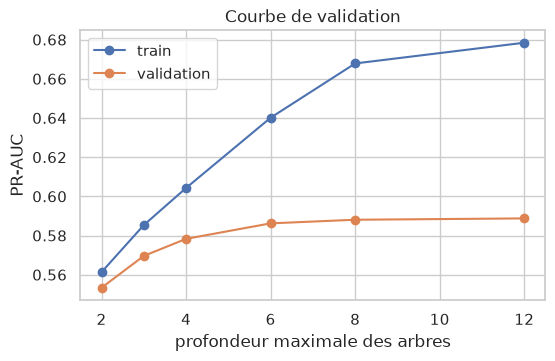

In [24]:
# 3) courbe de validation : profondeur de l'arbre
meilleurs = {k.replace("model__", ""): v for k, v in recherche.best_params_.items()}
reglages = {k: v for k, v in meilleurs.items() if k != "max_depth"}

profondeurs = [2, 3, 4, 6, 8, 12]
pr_train, pr_val = [], []
for d in profondeurs:
    m = HistGradientBoostingClassifier(class_weight="balanced", random_state=GRAINE, max_depth=d, **reglages).fit(Xf_r, y_fit_r)
    pr_train.append(average_precision_score(y_fit_r, m.predict_proba(Xf_r)[:, 1]))
    pr_val.append(average_precision_score(y_val, m.predict_proba(Xv_r)[:, 1]))

plt.figure(figsize=(6, 3.5))
plt.plot(profondeurs, pr_train, marker="o", label="train")
plt.plot(profondeurs, pr_val, marker="o", label="validation")
plt.xlabel("profondeur maximale des arbres")
plt.ylabel("PR-AUC")
plt.title("Courbe de validation")
plt.legend()
plt.show()

### Ce que je retiens du réglage

- **Gini ou entropie** : PR-AUC de 0,585 contre 0,588 pour la Random Forest. C'est équivalent, ce choix ne change presque rien.
- **Recherche aléatoire** (8 combinaisons, 3 plis, 100 secondes) : le meilleur score en validation croisée est de 0,583, et les 5 meilleures combinaisons sont toutes entre 0,579 et 0,583, avec un écart-type de 0,006 à 0,010. Les différences sont dans le bruit : **le réglage fin n'apporte presque rien**. Les réglages retenus sont `learning_rate=0,03`, `max_depth=8`, `max_leaf_nodes=63`, `min_samples_leaf=100` et `max_iter=300`.
- **Courbe de validation** : le score sur la validation monte de 0,553 (profondeur 2) jusqu'à environ 0,586 (profondeur 6), puis reste presque plat (0,588 à profondeur 8, 0,589 à 12). Pendant ce temps le score sur le train continue de monter (de 0,56 à 0,68) : au-delà d'environ 6 de profondeur, le modèle **apprend le train par cœur** sans mieux généraliser. La profondeur 8 que j'ai gardée est sur le plateau.
- Ce que j'en conclus : la limite vient probablement plus **des données** (ce qu'on sait sur l'accident) que des réglages du modèle. C'est une hypothèse, mais elle est cohérente avec le fait que même la régression logistique n'est pas très loin.

## 10. Résultats, limites et pistes d'amélioration

**Le modèle final** : un Gradient Boosting avec les meilleurs réglages trouvés dans la partie 9, entraîné sur **tout le jeu d'entraînement** (et pas seulement le sous-échantillon). J'ai gardé `class_weight='balanced'` pour gérer le déséquilibre (voir partie 7).

**Le seuil de décision** : par défaut, un modèle dit « grave » quand sa probabilité dépasse 0,5. Comme les graves sont rares, ce seuil n'est pas forcément le meilleur. Je choisis le seuil qui maximise le **F1 sur la validation** (pas sur le test), puis je l'applique au test.

**Le test** : c'est la première fois que j'utilise ces données. Ce score est celui que je peux annoncer.

In [25]:
from sklearn.metrics import (ConfusionMatrixDisplay, PrecisionRecallDisplay, classification_report,
                             precision_recall_curve)

# 1) le modèle final et le seuil (choisi sur la validation)
modele_final = Pipeline([("prep", clone(preprocesseur)),
                         ("model", HistGradientBoostingClassifier(class_weight="balanced", random_state=GRAINE, **meilleurs))])

modele_val = clone(modele_final).fit(X_fit_r, y_fit_r)
proba_val = modele_val.predict_proba(X_val)[:, 1]
prec, rapp, seuils = precision_recall_curve(y_val, proba_val)
f1_seuils = 2 * prec[:-1] * rapp[:-1] / (prec[:-1] + rapp[:-1] + 1e-12)
seuil = float(seuils[np.argmax(f1_seuils)])
print(f"seuil choisi sur la validation : {seuil:.2f}")

# 2) entraînement sur tout le train, évaluation sur le test
modele_final.fit(X_train, y_train)
proba_test = modele_final.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= seuil).astype(int)

print()
print(classification_report(y_test, pred_test, target_names=["pas grave", "grave"], digits=3))
print("PR-AUC :", round(average_precision_score(y_test, proba_test), 3), "| ROC-AUC :", round(roc_auc_score(y_test, proba_test), 3))
print(f"Rappel : un modèle qui répond toujours 'pas grave' a {(1 - y_test.mean()) * 100:.1f} % d'accuracy")

seuil choisi sur la validation : 0.64

              precision    recall  f1-score   support

   pas grave      0.924     0.862     0.892     20498
       grave      0.518     0.676     0.587      4499

    accuracy                          0.829     24997
   macro avg      0.721     0.769     0.739     24997
weighted avg      0.851     0.829     0.837     24997

PR-AUC : 0.595 | ROC-AUC : 0.869
Rappel : un modèle qui répond toujours 'pas grave' a 82.0 % d'accuracy


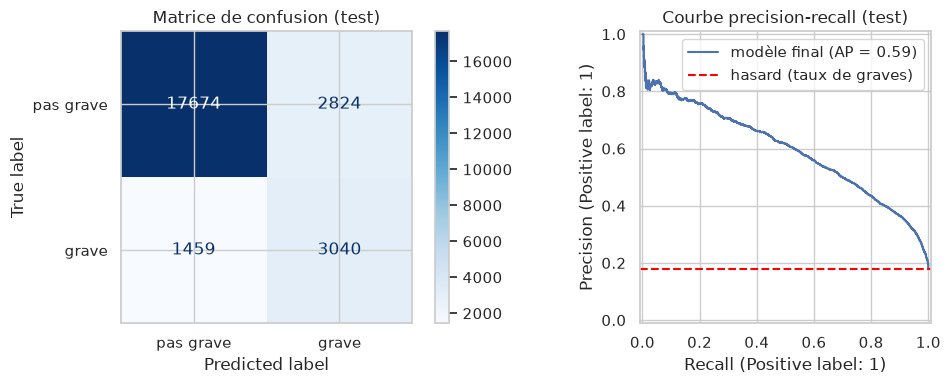

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=["pas grave", "grave"], cmap="Blues", ax=axes[0])
axes[0].set_title("Matrice de confusion (test)")
PrecisionRecallDisplay.from_predictions(y_test, proba_test, ax=axes[1], name="modèle final")
axes[1].axhline(y_test.mean(), color="red", linestyle="--", label="hasard (taux de graves)")
axes[1].set_title("Courbe precision-recall (test)")
axes[1].legend()
plt.tight_layout()
plt.show()

In [27]:
# tableau récapitulatif
final = scores(y_test, proba_test, seuil)
ligne_finale = pd.DataFrame([{**final, "temps (s)": np.nan}], index=["MODÈLE FINAL (test)"])
recap = pd.concat([tableau_modeles.assign(jeu="validation"), ligne_finale.assign(jeu="test")]).round(3)
display(recap)

,precision,recall,F1,PR-AUC,ROC-AUC,accuracy,temps (s),jeu
Gradient Boosting,0.428,0.798,0.557,0.587,0.866,0.770,1.9,validation
Random Forest,0.499,0.674,0.574,0.585,0.863,0.818,2.2,validation
Régression logistique,0.414,0.806,0.547,0.552,0.855,0.758,1.9,validation
Arbre de décision,0.373,0.821,0.513,0.510,0.835,0.718,0.6,validation
Dummy (toujours la classe majoritaire),0.000,0.000,0.000,0.181,0.500,0.819,0.1,validation
MODÈLE FINAL (test),0.518,0.676,0.587,0.595,0.869,0.829,NaN,test


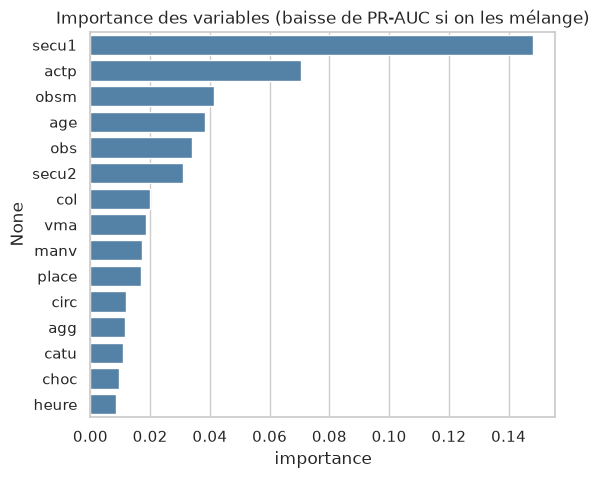

secu1    0.1483
actp     0.0704
obsm     0.0413
age      0.0385
obs      0.0340
secu2    0.0309
col      0.0200
vma      0.0186
manv     0.0172
place    0.0169
circ     0.0118
agg      0.0116
catu     0.0109
choc     0.0095
heure    0.0087
dtype: float64


In [28]:
# quelles variables comptent le plus ? (importance par permutation)
from sklearn.inspection import permutation_importance

echantillon = X_test.sample(n=min(4000, len(X_test)), random_state=GRAINE)
imp = permutation_importance(modele_final, echantillon, y_test.loc[echantillon.index], scoring="average_precision",
                             n_repeats=3, random_state=GRAINE, n_jobs=1)
importances = pd.Series(imp.importances_mean, index=echantillon.columns).sort_values(ascending=False).head(15)

plt.figure(figsize=(6, 5))
sns.barplot(x=importances.values, y=importances.index, color="steelblue")
plt.title("Importance des variables (baisse de PR-AUC si on les mélange)")
plt.xlabel("importance")
plt.show()
print(importances.round(4))

### Test de robustesse : et sans les variables d'équipement de sécurité ?

`secu1` est la variable la plus importante, loin devant les autres, alors que l'EDA montre que sa catégorie « non renseigné » n'est presque jamais grave. Pour savoir si le modèle dépend trop d'elle, je ré-entraîne le même modèle **sans `secu1` ni `secu2`** et je compare. Ce n'est qu'une analyse : je garde le modèle final, je ne l'ai pas choisi avec le test.

In [29]:
sans = [c for c in COL_CAT if c not in ("secu1", "secu2")]
prep_sans = ColumnTransformer([("num", transfo_num, COL_NUM), ("cat", transfo_cat, sans)])
modele_sans = Pipeline([("prep", prep_sans),
                        ("model", HistGradientBoostingClassifier(class_weight="balanced", random_state=GRAINE, **meilleurs))])
modele_sans.fit(X_train[COL_NUM + sans], y_train)
proba_sans = modele_sans.predict_proba(X_test[COL_NUM + sans])[:, 1]

pr_complet = average_precision_score(y_test, proba_test)
pr_sans = average_precision_score(y_test, proba_sans)
print(f"PR-AUC avec toutes les variables : {pr_complet:.3f}")
print(f"PR-AUC sans secu1 et secu2       : {pr_sans:.3f}")
if pr_complet - pr_sans < 0.02:
    print("=> Le modèle garde presque le même niveau sans ces variables : il ne dépend pas d'elles seules.")
else:
    print("=> Le score baisse nettement sans ces variables : une grande partie du signal vient d'elles, "
          "donc il faut être prudent sur leur interprétation.")

PR-AUC avec toutes les variables : 0.595
PR-AUC sans secu1 et secu2       : 0.580
=> Le modèle garde presque le même niveau sans ces variables : il ne dépend pas d'elles seules.


### Conclusions, limites et pistes d'amélioration

**Résultats sur le test** (24 997 personnes, dont 4 499 graves) :
- **PR-AUC de 0,595**, contre 0,180 pour le hasard : le modèle classe les personnes environ 3,3 fois mieux. **ROC-AUC de 0,869**.
- Au seuil de 0,64 (choisi sur la validation), le modèle trouve **3 040 des 4 499 graves** (recall 0,676), mais en rate 1 459. Sur les 5 864 personnes qu'il signale comme graves, 3 040 le sont vraiment (precision 0,518) et 2 824 sont de fausses alertes : environ une alerte sur deux est fausse.
- L'**accuracy est de 0,829**, seulement 0,9 point au-dessus du modèle qui répond toujours « pas grave » (0,820) : c'est la preuve qu'elle ne suffit pas pour juger ce problème.
- Le résultat sur le test (PR-AUC 0,595) est proche de celui sur la validation (environ 0,587) : le score est **stable**, il n'y a pas de gros sur-apprentissage.

**Les variables les plus importantes** : l'équipement de sécurité (`secu1`) est loin devant (0,148), puis l'action du piéton (`actp`, 0,070), l'obstacle mobile heurté (`obsm`, 0,041), l'âge (0,039), l'obstacle fixe heurté (`obs`, 0,034) et l'équipement secondaire (`secu2`, 0,031). La vitesse autorisée (`vma`) arrive plus bas (0,019).

**Test de robustesse** : sans `secu1` ni `secu2`, la PR-AUC passe de 0,595 à 0,580. Le modèle perd peu (0,015), donc il ne dépend pas seulement de ces deux variables : il retrouve une bonne partie de l'information ailleurs (type de véhicule, catégorie d'usager, action du piéton...). Mais ça veut aussi dire que l'importance par permutation de `secu1` (0,148) **surestime** ce qu'elle apporte seule, parce que des variables corrélées se remplacent entre elles (c'est une hypothèse, je ne l'ai pas vérifiée).

**Limites** :
1. **Un modèle descriptif, pas prédictif** : plusieurs variables (point de choc, obstacle heurté, type de collision, manœuvre) ne sont connues qu'après l'accident. Le modèle explique la gravité d'accidents déjà arrivés, il ne prévoit pas le risque avant.
2. **Les valeurs « non renseigné »** sont presque jamais graves (0 % pour le sexe, 2,8 % pour l'équipement). Une partie du score vient peut-être de la façon dont la fiche est remplie et pas du fait que la personne est gravement blessée. Mon test de robustesse montre que le modèle tient sans les variables d'équipement, mais il ne permet pas de séparer l'effet réel de l'équipement et cet effet de saisie.
3. **Corrélation n'est pas cause** : le casque est associé à plus de cas graves parce qu'il concerne des véhicules plus dangereux. Les importances de variables ne disent pas « si on change ça, le risque change ».
4. **Le label regroupe** tué et hospitalisé, deux situations très différentes, et la définition de « hospitalisé » a changé en 2018.
5. **Mon choix sur `lieux`** (garder la route à la vitesse la plus élevée) est une hypothèse.
6. **Une seule année (2023) et un seul découpage train/test** : je n'ai pas d'intervalle de confiance, donc les petites différences entre modèles (0,002) ne sont pas interprétables.
7. **Le score n'est pas une vraie probabilité** : avec `class_weight`, il est gonflé pour les cas graves.
8. **La localisation** (département, coordonnées) n'est pas utilisée.

**Pistes d'amélioration** : ajouter les années 2019 à 2022 et valider d'une année sur l'autre (entraîner sur le passé, tester sur l'année suivante), tester XGBoost ou LightGBM, utiliser la localisation, calibrer les probabilités, et choisir le seuil selon le coût réel d'une fausse alerte par rapport à un cas grave manqué.

## 11. Sauvegarde du modèle et déploiement

Je sauvegarde tout ce qu'il faut pour refaire une prédiction plus tard sans réentraîner : le **pipeline complet** (préparation des données + modèle), le **seuil** choisi, la liste des colonnes, et des **valeurs par défaut** (médiane ou valeur la plus fréquente de chaque colonne), qui servent à compléter les informations qu'un utilisateur ne donne pas.

Ensuite, `app.py` est une petite application web (Streamlit) qui charge ce fichier : l'utilisateur renseigne quelques informations (âge, heure, type de véhicule...) et le modèle donne un score de risque entre 0 et 1. Ce score n'est pas une probabilité exacte, parce que le modèle a été entraîné en donnant plus de poids aux cas graves, qui sont rares. Pour la lancer : `pip install streamlit`, puis `streamlit run app.py`.

In [30]:
import joblib

defauts = {}
for col in COL_NUM:
    defauts[col] = float(X_train[col].median())
for col in COL_CAT:
    defauts[col] = str(X_train[col].mode()[0])

os.makedirs("modele", exist_ok=True)
joblib.dump({"pipeline": modele_final, "seuil": seuil, "colonnes": COL_NUM + COL_CAT, "defauts": defauts},
            "modele/modele_gravite.joblib")
print("taille du fichier :", round(os.path.getsize("modele/modele_gravite.joblib") / 1e6, 1), "Mo")

# test : je recharge le modèle et je refais une prédiction
paquet = joblib.load("modele/modele_gravite.joblib")
exemple = pd.DataFrame([paquet["defauts"]], columns=paquet["colonnes"])
print("score de risque pour un profil moyen :", round(float(paquet["pipeline"].predict_proba(exemple)[0, 1]), 3))

taille du fichier : 2.1 Mo
score de risque pour un profil moyen : 0.1


### Pour aller plus loin
- ajouter d'autres années (2019 à 2022) pour avoir plus de données ;
- utiliser la localisation (département, coordonnées) avec un encodage adapté ;
- tester d'autres modèles (XGBoost, LightGBM) et une optimisation du seuil selon le coût réel d'une erreur ;
- déployer l'application en ligne (Streamlit Community Cloud).